# Preprocessing: Urban Street Tree Classification

**Dataset:** Urban Street Tree Classification  
**Source:** Kaggle dataset by `erickendric`  
**Task:** 23-class tree species image classification

This notebook prepares a clean and reproducible dataset for CNN experiments.

The preprocessing pipeline is deliberately separated from model training. Its purpose is to:

1. Verify the supplied train/validation/test structure.
2. Check image integrity.
3. Inspect image properties.
4. Check class distributions.
5. Detect exact duplicate images.
6. Detect cross-split near-duplicates.
7. Review near-duplicates before removal.
8. Build a clean dataset copy without confirmed leakage.
9. Define identical model-input preprocessing for all CNN experiments.
10. Construct PyTorch `ImageFolder` datasets and `DataLoader`s.
11. Verify that the final dataset is ready for baseline training.

> **Important:** The original Kaggle dataset under `/kaggle/input` is treated as read-only. No source images are deleted or modified. Confirmed exclusions are applied only when constructing `/kaggle/working/clean_tree`.

## 1. Imports, Reproducibility, and Configuration

This section imports the libraries used throughout preprocessing and establishes a fixed random seed.

A fixed seed improves reproducibility for operations such as visualization sampling and later training experiments. The seed does not make every CUDA operation perfectly deterministic, but it provides a consistent experimental starting point.

The dataset path is kept configurable so that the notebook can be reused if the Kaggle mount path changes.

In [6]:
from pathlib import Path
from collections import Counter
from itertools import combinations
import hashlib
import os
import random
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, UnidentifiedImageError

import torch
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.datasets import ImageFolder

# Perceptual hashing is used for near-duplicate screening.
try:
    import imagehash
except ImportError:
    !pip install -q ImageHash
    import imagehash

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Dataset configuration
# ------------------------------------------------------------
DATASET_ROOT = Path(
    "/kaggle/input/datasets/erickendric/"
    "tree-dataset-of-urban-street-classification-tree/tree"
)

SOURCE_TRAIN_DIR = DATASET_ROOT / "train"
SOURCE_VAL_DIR = DATASET_ROOT / "val"
SOURCE_TEST_DIR = DATASET_ROOT / "test"

CLEAN_ROOT = Path("/kaggle/working/clean_tree")

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".webp", ".tif", ".tiff"
}

EXPECTED_NUM_CLASSES = 23

print("Dataset root:", DATASET_ROOT)
print("Train exists:", SOURCE_TRAIN_DIR.exists())
print("Val exists  :", SOURCE_VAL_DIR.exists())
print("Test exists :", SOURCE_TEST_DIR.exists())

Dataset root: /kaggle/input/datasets/erickendric/tree-dataset-of-urban-street-classification-tree/tree
Train exists: True
Val exists  : True
Test exists : True


## 2. Dataset Structure Verification

The dataset is expected to follow the standard `ImageFolder` directory structure:

```text
tree/
├── train/
│   ├── class_1/
│   ├── class_2/
│   └── ...
├── val/
│   ├── class_1/
│   ├── class_2/
│   └── ...
└── test/
    ├── class_1/
    ├── class_2/
    └── ...
```

The supplied split is preserved. This notebook does **not** randomly re-split the dataset.

The class directory names are used as the target labels.

In [7]:
assert DATASET_ROOT.exists(), f"Dataset root does not exist: {DATASET_ROOT}"
assert SOURCE_TRAIN_DIR.exists(), "Training directory is missing."
assert SOURCE_VAL_DIR.exists(), "Validation directory is missing."
assert SOURCE_TEST_DIR.exists(), "Test directory is missing."

SPLIT_DIRS = {
    "train": SOURCE_TRAIN_DIR,
    "val": SOURCE_VAL_DIR,
    "test": SOURCE_TEST_DIR,
}

def get_classes(split_dir):
    return sorted([
        p.name for p in split_dir.iterdir()
        if p.is_dir()
    ])

train_classes = get_classes(SOURCE_TRAIN_DIR)
val_classes = get_classes(SOURCE_VAL_DIR)
test_classes = get_classes(SOURCE_TEST_DIR)

print("Number of classes:")
print("Train:", len(train_classes))
print("Val  :", len(val_classes))
print("Test :", len(test_classes))

assert len(train_classes) == EXPECTED_NUM_CLASSES
assert train_classes == val_classes
assert train_classes == test_classes

print("\nClass sets are identical across train / val / test.")
print("\nClasses:")
for i, name in enumerate(train_classes):
    print(f"{i:2d}: {name}")

Number of classes:
Train: 23
Val  : 23
Test : 23

Class sets are identical across train / val / test.

Classes:
 0: Acer palmatum
 1: Cedrus deodara
 2: Celtis sinensis
 3: Cinnamomum camphora (Linn) Presl
 4: Elaeocarpus decipiens
 5: Flowering cherry
 6: Ginkgo biloba
 7: Koelreuteria paniculata
 8: Lagerstroemia indica
 9: Liquidambar formosana
10: Liriodendron chinense
11: Magnolia grandiflora L
12: Magnolia liliflora Desr
13: Michelia chapensis
14: Osmanthus fragrans
15: Photinia serratifolia
16: Platanus
17: Prunus cerasifera f. atropurpurea
18: Salix babylonica
19: Sapindus saponaria
20: Styphnolobium japonicum
21: Triadica sebifera
22: Zelkova serrata


## 3. Collect Image Metadata

Every image file is recorded in a single metadata table.

The table stores:

- split
- class
- filename
- full path

This table becomes the basis for integrity checks, duplicate detection, and later removal manifests.

In [8]:
def collect_images(split_name, split_dir):
    records = []

    for class_dir in sorted(split_dir.iterdir()):
        if not class_dir.is_dir():
            continue

        class_name = class_dir.name

        for path in sorted(class_dir.rglob("*")):
            if (
                path.is_file()
                and path.suffix.lower() in IMAGE_EXTENSIONS
            ):
                records.append({
                    "split": split_name,
                    "class": class_name,
                    "filename": path.name,
                    "path": str(path)
                })

    return records


all_records = []

for split_name, split_dir in SPLIT_DIRS.items():
    records = collect_images(split_name, split_dir)
    all_records.extend(records)
    print(f"{split_name.capitalize():5s}: {len(records):,} images")

all_records_df = pd.DataFrame(all_records)

print(f"\nTotal images: {len(all_records_df):,}")
assert len(all_records_df) > 0

Train: 3,850 images
Val  : 482 images
Test : 472 images

Total images: 4,804


## 4. Class Distribution

Class distribution is inspected before training.

The baseline model is not artificially balanced at this stage. Validation and test sets remain representative of the supplied dataset.

Class imbalance is handled later as an explicit experiment using either class-weighted loss or weighted sampling.

In [9]:
class_distribution = (
    all_records_df
    .groupby(["split", "class"])
    .size()
    .unstack(fill_value=0)
)

display(class_distribution)

print("\nSplit totals:")
display(
    all_records_df.groupby("split").size().rename("images").to_frame()
)

print("\nTraining class counts:")
train_counts = (
    all_records_df[all_records_df["split"] == "train"]
    .groupby("class")
    .size()
    .sort_values()
)
display(train_counts.to_frame("count"))

print(
    f"\nTraining imbalance ratio "
    f"(largest / smallest): "
    f"{train_counts.max() / train_counts.min():.2f}x"
)

class,Acer palmatum,Cedrus deodara,Celtis sinensis,Cinnamomum camphora (Linn) Presl,Elaeocarpus decipiens,Flowering cherry,Ginkgo biloba,Koelreuteria paniculata,Lagerstroemia indica,Liquidambar formosana,...,Michelia chapensis,Osmanthus fragrans,Photinia serratifolia,Platanus,Prunus cerasifera f. atropurpurea,Salix babylonica,Sapindus saponaria,Styphnolobium japonicum,Triadica sebifera,Zelkova serrata
split,,,,,,,,,,,,,,,,,,,,,
test,20,15,23,29,21,13,28,28,8,20,...,19,21,15,24,12,16,28,19,19,23
train,162,125,188,234,172,106,228,223,65,168,...,154,173,120,193,99,136,224,157,154,185
val,21,16,24,29,23,13,28,28,8,21,...,19,22,15,24,12,17,28,19,19,23



Split totals:


,images
split,
test,472
train,3850
val,482



Training class counts:


,count
class,
Lagerstroemia indica,65
Prunus cerasifera f. atropurpurea,99
Flowering cherry,106
Photinia serratifolia,120
Cedrus deodara,125
Salix babylonica,136
Michelia chapensis,154
Triadica sebifera,154
Styphnolobium japonicum,157



Training imbalance ratio (largest / smallest): 3.60x


## 5. Image Integrity Check

Each image is opened and verified using PIL.

The check identifies:

- unreadable files
- corrupted files
- image format
- color mode
- width and height
- aspect ratio

Invalid files are **reported**, not deleted from the original Kaggle dataset.

Only valid images are eligible for the clean dataset.

In [10]:
integrity_results = []

for record in all_records:
    path = Path(record["path"])

    result = {
        "split": record["split"],
        "class": record["class"],
        "filename": record["filename"],
        "path": str(path),
        "valid": False,
        "format": None,
        "mode": None,
        "width": None,
        "height": None,
        "aspect_ratio": None,
        "error": None,
    }

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            width, height = img.size

            result["valid"] = True
            result["format"] = img.format
            result["mode"] = img.mode
            result["width"] = width
            result["height"] = height
            result["aspect_ratio"] = width / height if height > 0 else None

    except Exception as e:
        result["error"] = f"{type(e).__name__}: {e}"

    integrity_results.append(result)

integrity_df = pd.DataFrame(integrity_results)

print("Total images :", len(integrity_df))
print("Valid images :", int(integrity_df["valid"].sum()))
print("Invalid images:", int((~integrity_df["valid"]).sum()))

invalid_df = integrity_df[~integrity_df["valid"]].copy()

if invalid_df.empty:
    print("\n✓ No corrupted or unreadable images detected.")
else:
    print(f"\n⚠ {len(invalid_df)} invalid images detected.")
    display(invalid_df)

Total images : 4804
Valid images : 4804
Invalid images: 0

✓ No corrupted or unreadable images detected.


## 6. Image Properties

The dataset may contain different resolutions, formats, and aspect ratios.

The model input will eventually be converted to RGB and resized/cropped to `224 × 224`.

The original image files are not modified.

The purpose of this section is descriptive: it confirms what the source dataset contains before transformation.

In [11]:
valid_df = integrity_df[integrity_df["valid"]].copy()

print("Color modes:")
display(valid_df["mode"].value_counts().rename("count").to_frame())

print("\nImage formats:")
display(valid_df["format"].value_counts().rename("count").to_frame())

print("\nWidth statistics:")
display(valid_df["width"].describe().to_frame("width"))

print("\nHeight statistics:")
display(valid_df["height"].describe().to_frame("height"))

print("\nAspect-ratio statistics:")
display(valid_df["aspect_ratio"].describe().to_frame("aspect_ratio"))

Color modes:


,count
mode,
RGB,4804



Image formats:


,count
format,
JPEG,4804



Width statistics:


,width
count,4804.000000
mean,1576.408826
std,94.996123
min,837.000000
25%,1600.000000
50%,1600.000000
75%,1600.000000
max,1600.000000



Height statistics:


,height
count,4804.000000
mean,1223.844921
std,96.007766
min,798.000000
25%,1200.000000
50%,1200.000000
75%,1200.000000
max,1600.000000



Aspect-ratio statistics:


,aspect_ratio
count,4804.000000
mean,1.298969
std,0.139363
min,0.523125
25%,1.333333
50%,1.333333
75%,1.333333
max,2.005013


## 7. Sample Image Visualization

A small random sample is displayed to visually verify:

- class labels
- image quality
- framing
- backgrounds
- typical tree appearance
- whether important visual information is commonly near the image edges

This is an inspection step only. It does not alter the dataset.

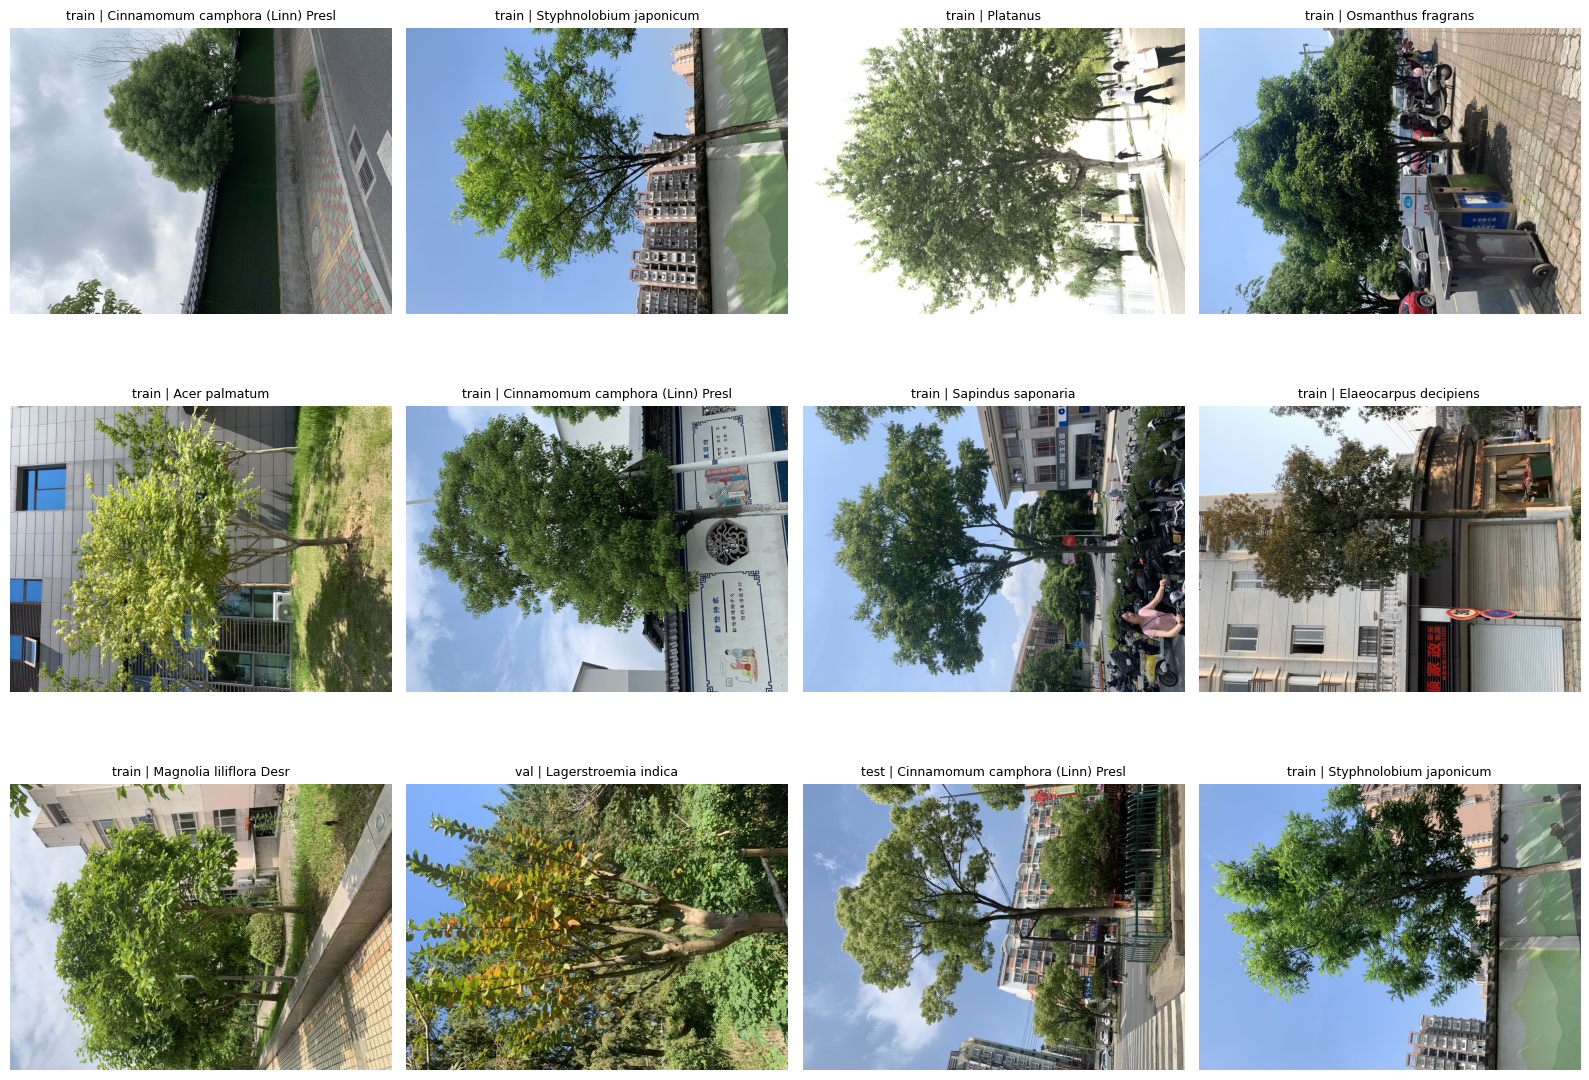

In [12]:
def show_random_samples(metadata_df, n=12, seed=SEED):
    sample_n = min(n, len(metadata_df))
    sample = metadata_df.sample(sample_n, random_state=seed)

    fig, axes = plt.subplots(3, 4, figsize=(16, 12))
    axes = axes.ravel()

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, sample.iterrows()):
        try:
            with Image.open(row["path"]) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(
                f'{row["split"]} | {row["class"]}',
                fontsize=9
            )
        except Exception:
            ax.set_title("Could not load image")

        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_random_samples(valid_df, n=12)

## 8. Exact Duplicate Detection

Exact duplicates are detected using SHA-256.

An identical SHA-256 hash means the file bytes are identical.

The critical case is a duplicate occurring across different dataset splits. If the same image exists in training and validation/test, the evaluation result can be artificially inflated because the model has already seen the exact image during training.

Policy:

- train + val/test → remove the evaluation copy
- val + test → keep test and remove val
- duplicates within val/test → keep one evaluation copy
- train-only duplicates → no split leakage

In [13]:
def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)

    return digest.hexdigest()


sha_records = []

for _, row in valid_df.iterrows():
    path = row["path"]

    sha_records.append({
        "path": path,
        "split": row["split"],
        "class": row["class"],
        "filename": row["filename"],
        "sha256": sha256_file(path)
    })

hash_df = pd.DataFrame(sha_records)

duplicate_groups = (
    hash_df.groupby("sha256")
    .size()
    .sort_values(ascending=False)
)

duplicate_groups = duplicate_groups[duplicate_groups > 1]

print("Exact duplicate groups:", len(duplicate_groups))
print("Files participating in duplicate groups:", int(duplicate_groups.sum()))

if duplicate_groups.empty:
    print("\n✓ No exact duplicate files detected.")
else:
    display(duplicate_groups.head(20).rename("file_count").to_frame())

Exact duplicate groups: 45
Files participating in duplicate groups: 94


,file_count
sha256,
ee2e18c83d9934987e56efc73c881458b2e7a41252efb6d398e7b69cd99b6b6f,3
b2d2ff00fae734f5a1508e3d6c132b39588ebbf4ae91469dc524fc01c5597395,3
4631844466fcdd04a7bf2bbf01f6d04d68ce907320fdd171026fbfe8c6f42b96,3
f94f3b418124f1d48f113eb8fee79ced838296c5915a575bf106a395109034f0,3
9bceb6fe6d4d72e5fd245c1da0bb995be06f91cf7687d6724638a4027bafe4d3,2
27933473e2ecee735f1b77622aa3eb0d452edb2fc94b45d846324940eadcf3c9,2
fd010a2510104682f0d66ffc3cab4a8a18a90f723ae0f87d6f6dfbb1fd376566,2
df922d5defe1a7a6e1ca8f08e82786c915dc025b39d0f94087292444f9dfa791,2
f07af54a84f92d7c48c2a81201311053025b73e129502014f71d1da4c6ba566e,2


## 9. Cross-Split Exact Duplicate Analysis

Only duplicates crossing a split boundary represent potential evaluation leakage.

The output below lists the affected images and their splits.

No files are deleted at this point. A removal manifest is generated first so that every exclusion is auditable.

In [14]:
cross_split_exact_groups = []

for sha, group in hash_df.groupby("sha256"):
    if group["split"].nunique() > 1:
        cross_split_exact_groups.append(group)

if cross_split_exact_groups:
    cross_split_exact_df = pd.concat(
        cross_split_exact_groups,
        ignore_index=True
    )
else:
    cross_split_exact_df = pd.DataFrame(
        columns=hash_df.columns
    )

print(
    "Files involved in cross-split exact duplicates:",
    len(cross_split_exact_df)
)

if cross_split_exact_df.empty:
    print("✓ No cross-split exact duplicates detected.")
else:
    display(
        cross_split_exact_df.sort_values(
            ["sha256", "split", "class", "filename"]
        )
    )

Files involved in cross-split exact duplicates: 23


,path,split,class,filename,sha256
0,/kaggle/input/datasets/erickendric/tree-datase...,train,Zelkova serrata,Zelkova serrata_tree_1 (61).jpg,0ba9c200e4522d377576ac23ffce52b8a0d70c5b44abbd...
1,/kaggle/input/datasets/erickendric/tree-datase...,val,Zelkova serrata,Zelkova serrata_tree_1 (146).jpg,0ba9c200e4522d377576ac23ffce52b8a0d70c5b44abbd...
2,/kaggle/input/datasets/erickendric/tree-datase...,train,Flowering cherry,Flowering cherry_tree_1 (129).jpg,2479d80949ca5d28037302670b9234415c87d3fc985543...
3,/kaggle/input/datasets/erickendric/tree-datase...,val,Flowering cherry,Flowering cherry_tree_1 (58).jpg,2479d80949ca5d28037302670b9234415c87d3fc985543...
4,/kaggle/input/datasets/erickendric/tree-datase...,train,Photinia serratifolia,Photinia serratifolia_tree_1 (41).JPG,3399e14f23900f317971241c304362af0a06023feb8889...
5,/kaggle/input/datasets/erickendric/tree-datase...,val,Photinia serratifolia,Photinia serratifolia_tree_1 (129).JPG,3399e14f23900f317971241c304362af0a06023feb8889...
6,/kaggle/input/datasets/erickendric/tree-datase...,train,Photinia serratifolia,Photinia serratifolia_tree_1 (139).JPG,4631844466fcdd04a7bf2bbf01f6d04d68ce907320fdd1...
7,/kaggle/input/datasets/erickendric/tree-datase...,train,Photinia serratifolia,Photinia serratifolia_tree_1 (68).JPG,4631844466fcdd04a7bf2bbf01f6d04d68ce907320fdd1...
8,/kaggle/input/datasets/erickendric/tree-datase...,val,Photinia serratifolia,Photinia serratifolia_tree_1 (117).JPG,4631844466fcdd04a7bf2bbf01f6d04d68ce907320fdd1...
9,/kaggle/input/datasets/erickendric/tree-datase...,train,Sapindus saponaria,Sapindus saponaria_tree_1 (11).jpg,691f445bcb28640aae93e41f7373260426a730f662c7b6...


## 10. Build Exact-Duplicate Removal Manifest

The source dataset is read-only, so the notebook does not physically delete images.

Instead, this section creates an explicit list of files that must be excluded from the clean dataset.

The policy is intentionally conservative:

1. If a duplicate exists in train, keep the train copy and remove val/test copies.
2. If there is no train copy but a duplicate exists in test, keep test and remove val.
3. If duplicates exist only in val, keep one deterministic copy.

In [15]:
exact_removals = []
seen_exact_paths = set()

def normalize_path(path):
    return os.path.normpath(str(path))


def add_exact_removal(row, reason):
    path = normalize_path(row["path"])

    if path not in seen_exact_paths:
        seen_exact_paths.add(path)

        exact_removals.append({
            "split": row["split"],
            "class": row["class"],
            "filename": row["filename"],
            "path": path,
            "reason": reason
        })


for _, group in cross_split_exact_df.groupby("sha256"):
    splits = set(group["split"])

    if "train" in splits:
        remove_df = group[group["split"] != "train"]
        reason = "exact_duplicate_keep_train_remove_eval"

    elif "test" in splits:
        remove_df = group[group["split"] != "test"]
        reason = "exact_duplicate_keep_test_remove_val"

    elif "val" in splits:
        remove_df = group.sort_values("path").iloc[1:]
        reason = "exact_duplicate_keep_first_val"

    else:
        remove_df = group.iloc[0:0]
        reason = "unused"

    for _, row in remove_df.iterrows():
        add_exact_removal(row, reason)


# Also remove repeated evaluation copies within val/test.
for split in ["val", "test"]:
    split_df = hash_df[hash_df["split"] == split]

    for _, group in split_df.groupby("sha256"):
        if len(group) <= 1:
            continue

        group_sorted = group.sort_values("path")

        remaining = group_sorted[
            ~group_sorted["path"].isin(seen_exact_paths)
        ]

        for _, row in remaining.iloc[1:].iterrows():
            add_exact_removal(
                row,
                reason=f"within_{split}_exact_duplicate"
            )


exact_removals_df = pd.DataFrame(
    exact_removals,
    columns=[
        "split",
        "class",
        "filename",
        "path",
        "reason"
    ]
)

print(
    "Exact files scheduled for exclusion:",
    len(exact_removals_df)
)

if not exact_removals_df.empty:
    display(
        exact_removals_df
        .groupby(["split", "reason"])
        .size()
        .rename("count")
        .to_frame()
    )

exact_removals_df.to_csv(
    "/kaggle/working/exact_removals.csv",
    index=False
)

Exact files scheduled for exclusion: 14


count
split reason                                       
val   exact_duplicate_keep_train_remove_eval     10
      within_val_exact_duplicate                  4

## 11. Near-Duplicate Detection

Exact hashing cannot identify images that are visually the same but have been:

- resized
- recompressed
- slightly edited
- saved in another format

Perceptual hashing (pHash) is therefore used to identify candidate near-duplicate pairs.

A low Hamming distance means that the images have similar perceptual hashes.

> **Important:** A near-duplicate match is only a candidate. It is not automatically treated as leakage. The pairs must be manually inspected.

In [16]:
# pHash on the valid image set.
phash_records = []

for _, row in valid_df.iterrows():
    try:
        with Image.open(row["path"]) as img:
            phash_value = imagehash.phash(img.convert("RGB"))

        phash_records.append({
            "path": row["path"],
            "split": row["split"],
            "class": row["class"],
            "filename": row["filename"],
            "phash": phash_value
        })

    except Exception as e:
        print(f"Could not hash {row['path']}: {e}")


phash_df = pd.DataFrame(phash_records)

print("Perceptual hashes computed:", len(phash_df))

Perceptual hashes computed: 4804


## 12. Cross-Split Near-Duplicate Screening

The pairwise search is restricted to images from different splits because the primary purpose is detecting train/validation/test leakage.

With approximately 4,800 images this quadratic comparison is acceptable as a one-time preprocessing step.

The result is sorted by perceptual distance so that the most similar candidates appear first.

In [17]:
near_duplicate_rows = []

# Convert hash objects to a stable list for pairwise comparison.
phash_records = phash_df.to_dict("records")

for i, j in combinations(range(len(phash_records)), 2):
    a = phash_records[i]
    b = phash_records[j]

    if a["split"] == b["split"]:
        continue

    distance = a["phash"] - b["phash"]

    near_duplicate_rows.append({
        "distance": int(distance),
        "split_1": a["split"],
        "class_1": a["class"],
        "path_1": a["path"],
        "split_2": b["split"],
        "class_2": b["class"],
        "path_2": b["path"],
    })


near_duplicates_df = pd.DataFrame(near_duplicate_rows)

# Candidate threshold.
# This is for review, not automatic deletion.
NEAR_DUPLICATE_DISTANCE_THRESHOLD = 6

cross_split_near_df = (
    near_duplicates_df[
        near_duplicates_df["distance"]
        <= NEAR_DUPLICATE_DISTANCE_THRESHOLD
    ]
    .sort_values("distance")
    .reset_index(drop=True)
)

print(
    "Cross-split near-duplicate candidates:",
    len(cross_split_near_df)
)

if not cross_split_near_df.empty:
    display(cross_split_near_df.head(50))

Cross-split near-duplicate candidates: 25


,distance,split_1,class_1,path_1,split_2,class_2,path_2
0,0,train,Flowering cherry,/kaggle/input/datasets/erickendric/tree-datase...,val,Flowering cherry,/kaggle/input/datasets/erickendric/tree-datase...
1,0,train,Flowering cherry,/kaggle/input/datasets/erickendric/tree-datase...,val,Flowering cherry,/kaggle/input/datasets/erickendric/tree-datase...
2,0,train,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...
3,0,train,Liquidambar formosana,/kaggle/input/datasets/erickendric/tree-datase...,val,Liquidambar formosana,/kaggle/input/datasets/erickendric/tree-datase...
4,0,train,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...
5,0,train,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...
6,0,train,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...,val,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...
7,0,train,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...
8,0,train,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...,val,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...
9,0,train,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...,val,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...


## 13. Export Near-Duplicate Pairs for Manual Review

Every near-duplicate candidate is copied into a review directory containing the two original images.

The review directory is:

```text
/kaggle/working/near_duplicate_review/
```

For each pair, the notebook also records a suggested removal.

The suggestion is **not automatically accepted**.

In [18]:
NEAR_REVIEW_DIR = Path(
    "/kaggle/working/near_duplicate_review"
)

NEAR_REVIEW_DIR.mkdir(
    parents=True,
    exist_ok=True
)

near_review_rows = []

for pair_id, (_, row) in enumerate(
    cross_split_near_df.iterrows(),
    start=1
):
    class_name = str(row["class_1"]).replace("/", "_")
    distance = int(row["distance"])

    pair_dir = (
        NEAR_REVIEW_DIR
        / f"pair_{pair_id:04d}_dist_{distance}_{class_name}"
    )

    pair_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    for side in [1, 2]:
        src = Path(row[f"path_{side}"])

        split = row[f"split_{side}"]
        class_side = row[f"class_{side}"]

        dst_name = (
            f"{split}__{class_side}__{src.name}"
        )

        dst = pair_dir / dst_name

        try:
            shutil.copy2(src, dst)
        except Exception as e:
            print(f"Could not copy {src}: {e}")

    split_1 = row["split_1"]
    split_2 = row["split_2"]

    if split_1 == "train" and split_2 in {"val", "test"}:
        suggested_remove = normalize_path(row["path_2"])
        suggested_reason = "near_duplicate_of_train_remove_eval"

    elif split_2 == "train" and split_1 in {"val", "test"}:
        suggested_remove = normalize_path(row["path_1"])
        suggested_reason = "near_duplicate_of_train_remove_eval"

    elif {split_1, split_2} == {"val", "test"}:
        if split_1 == "test":
            suggested_remove = normalize_path(row["path_2"])
        else:
            suggested_remove = normalize_path(row["path_1"])

        suggested_reason = "near_duplicate_keep_test_remove_val"

    else:
        suggested_remove = None
        suggested_reason = "manual_only"

    near_review_rows.append({
        "pair_id": pair_id,
        "distance": row["distance"],
        "split_1": split_1,
        "class_1": row["class_1"],
        "path_1": normalize_path(row["path_1"]),
        "split_2": split_2,
        "class_2": row["class_2"],
        "path_2": normalize_path(row["path_2"]),
        "suggested_remove_path": suggested_remove,
        "suggested_reason": suggested_reason,
    })


near_review_df = pd.DataFrame(near_review_rows)

near_review_df.to_csv(
    "/kaggle/working/near_duplicate_review.csv",
    index=False
)

print("Review directory:")
print(NEAR_REVIEW_DIR)

print("\nReview CSV:")
print("/kaggle/working/near_duplicate_review.csv")

display(near_review_df.head(50))

Review directory:
/kaggle/working/near_duplicate_review

Review CSV:
/kaggle/working/near_duplicate_review.csv


,pair_id,distance,split_1,class_1,path_1,split_2,class_2,path_2,suggested_remove_path,suggested_reason
0,1,0,train,Flowering cherry,/kaggle/input/datasets/erickendric/tree-datase...,val,Flowering cherry,/kaggle/input/datasets/erickendric/tree-datase...,/kaggle/input/datasets/erickendric/tree-datase...,near_duplicate_of_train_remove_eval
1,2,0,train,Flowering cherry,/kaggle/input/datasets/erickendric/tree-datase...,val,Flowering cherry,/kaggle/input/datasets/erickendric/tree-datase...,/kaggle/input/datasets/erickendric/tree-datase...,near_duplicate_of_train_remove_eval
2,3,0,train,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,/kaggle/input/datasets/erickendric/tree-datase...,near_duplicate_of_train_remove_eval
3,4,0,train,Liquidambar formosana,/kaggle/input/datasets/erickendric/tree-datase...,val,Liquidambar formosana,/kaggle/input/datasets/erickendric/tree-datase...,/kaggle/input/datasets/erickendric/tree-datase...,near_duplicate_of_train_remove_eval
4,5,0,train,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,/kaggle/input/datasets/erickendric/tree-datase...,near_duplicate_of_train_remove_eval
5,6,0,train,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,/kaggle/input/datasets/erickendric/tree-datase...,near_duplicate_of_train_remove_eval
6,7,0,train,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...,val,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...,/kaggle/input/datasets/erickendric/tree-datase...,near_duplicate_of_train_remove_eval
7,8,0,train,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,test,Magnolia grandiflora L,/kaggle/input/datasets/erickendric/tree-datase...,/kaggle/input/datasets/erickendric/tree-datase...,near_duplicate_of_train_remove_eval
8,9,0,train,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...,val,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...,/kaggle/input/datasets/erickendric/tree-datase...,near_duplicate_of_train_remove_eval
9,10,0,train,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...,val,Photinia serratifolia,/kaggle/input/datasets/erickendric/tree-datase...,/kaggle/input/datasets/erickendric/tree-datase...,near_duplicate_of_train_remove_eval


## 14. Confirmed Near-Duplicate Removals

Near-duplicate detection does not automatically remove images.

After visually inspecting the review directory, enter the paths that you have confirmed as duplicates.

For a conservative baseline, leave the list empty unless you have manually confirmed a pair.

Example:

```python
CONFIRMED_NEAR_REMOVALS = [
    "/kaggle/input/.../val/example.jpg",
]
```

This manual confirmation step prevents ordinary images of the same tree species from being incorrectly removed just because they look similar.

In [19]:
# ------------------------------------------------------------
# MANUAL REVIEW STEP
# ------------------------------------------------------------
# Add only paths that you have visually confirmed as
# near-duplicates / leakage.
#
# Example:
#
# CONFIRMED_NEAR_REMOVALS = [
#     "/kaggle/input/.../val/example.jpg",
# ]
#
# ------------------------------------------------------------

CONFIRMED_NEAR_REMOVALS = []

confirmed_near_remove_set = {
    normalize_path(p)
    for p in CONFIRMED_NEAR_REMOVALS
    if p is not None
}

print(
    "Confirmed near-duplicate removals:",
    len(confirmed_near_remove_set)
)

if confirmed_near_remove_set:
    display(
        near_review_df[
            near_review_df["path_1"].isin(
                confirmed_near_remove_set
            )
            |
            near_review_df["path_2"].isin(
                confirmed_near_remove_set
            )
        ]
    )
else:
    print(
        "No near-duplicates have been manually confirmed."
    )

Confirmed near-duplicate removals: 0
No near-duplicates have been manually confirmed.


## 15. Build the Final Removal Manifest

The final exclusion set combines:

- exact cross-split duplicates
- confirmed near-duplicates

This manifest is saved separately so the preprocessing decision is reproducible.

The original dataset remains untouched.

In [20]:
exact_remove_set = set(
    exact_removals_df["path"].astype(str)
) if not exact_removals_df.empty else set()

all_remove_set = (
    exact_remove_set
    | confirmed_near_remove_set
)

print("Exact duplicate exclusions:", len(exact_remove_set))
print("Near-duplicate exclusions :", len(confirmed_near_remove_set))
print("Total exclusions          :", len(all_remove_set))

# Save the exact and final manifests.
exact_removals_df.to_csv(
    "/kaggle/working/exact_removals_final.csv",
    index=False
)

final_removal_rows = []

for path in sorted(all_remove_set):
    if path in exact_remove_set:
        reason = "exact_duplicate"
    else:
        reason = "confirmed_near_duplicate"

    final_removal_rows.append({
        "path": path,
        "reason": reason
    })

final_removal_df = pd.DataFrame(final_removal_rows)

final_removal_df.to_csv(
    "/kaggle/working/final_removal_manifest.csv",
    index=False
)

display(final_removal_df.head(50))

Exact duplicate exclusions: 14
Near-duplicate exclusions : 0
Total exclusions          : 14


,path,reason
0,/kaggle/input/datasets/erickendric/tree-datase...,exact_duplicate
1,/kaggle/input/datasets/erickendric/tree-datase...,exact_duplicate
2,/kaggle/input/datasets/erickendric/tree-datase...,exact_duplicate
3,/kaggle/input/datasets/erickendric/tree-datase...,exact_duplicate
4,/kaggle/input/datasets/erickendric/tree-datase...,exact_duplicate
5,/kaggle/input/datasets/erickendric/tree-datase...,exact_duplicate
6,/kaggle/input/datasets/erickendric/tree-datase...,exact_duplicate
7,/kaggle/input/datasets/erickendric/tree-datase...,exact_duplicate
8,/kaggle/input/datasets/erickendric/tree-datase...,exact_duplicate
9,/kaggle/input/datasets/erickendric/tree-datase...,exact_duplicate


## 16. Build the Clean Dataset

Kaggle input data is read-only, so the clean dataset is constructed under:

```text
/kaggle/working/clean_tree/
```

The original directory structure and class names are preserved.

Only files in the final removal manifest are excluded.

This produces the dataset that should be used by the CNN experiments.

In [21]:
def build_clean_tree(source_root, clean_root, remove_set):
    if clean_root.exists():
        shutil.rmtree(clean_root)

    counts = {}

    for split in ["train", "val", "test"]:
        src_split = source_root / split
        dst_split = clean_root / split

        dst_split.mkdir(
            parents=True,
            exist_ok=True
        )

        split_count = 0

        for class_dir in sorted(src_split.iterdir()):
            if not class_dir.is_dir():
                continue

            dst_class_dir = dst_split / class_dir.name

            dst_class_dir.mkdir(
                parents=True,
                exist_ok=True
            )

            for file_path in sorted(class_dir.iterdir()):
                if not file_path.is_file():
                    continue

                if file_path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue

                if normalize_path(file_path) in remove_set:
                    continue

                shutil.copy2(
                    file_path,
                    dst_class_dir / file_path.name
                )

                split_count += 1

        counts[split] = split_count

    return counts


clean_counts = build_clean_tree(
    source_root=DATASET_ROOT,
    clean_root=CLEAN_ROOT,
    remove_set=all_remove_set
)

print("Clean dataset counts:")
for split, count in clean_counts.items():
    print(f"{split.capitalize():5s}: {count:,}")

print("\nClean dataset root:")
print(CLEAN_ROOT)

Clean dataset counts:
Train: 3,850
Val  : 468
Test : 472

Clean dataset root:
/kaggle/working/clean_tree


## 17. Point the ML Pipeline to the Clean Dataset

From this point onward, the original `/kaggle/input` dataset is no longer used for model input.

All CNN experiments should use:

```text
/kaggle/working/clean_tree/train
/kaggle/working/clean_tree/val
/kaggle/working/clean_tree/test
```

This makes the duplicate-removal decision part of the actual experimental dataset.

In [22]:
TRAIN_DIR = CLEAN_ROOT / "train"
VAL_DIR = CLEAN_ROOT / "val"
TEST_DIR = CLEAN_ROOT / "test"

assert TRAIN_DIR.exists()
assert VAL_DIR.exists()
assert TEST_DIR.exists()

print("Train:", TRAIN_DIR)
print("Val  :", VAL_DIR)
print("Test :", TEST_DIR)

Train: /kaggle/working/clean_tree/train
Val  : /kaggle/working/clean_tree/val
Test : /kaggle/working/clean_tree/test


## 18. Verify the Clean Dataset

The clean dataset is checked again after construction.

This prevents a preprocessing bug from silently producing:

- missing classes
- inconsistent class mappings
- empty class directories
- unexpected file counts

The final dataset is the dataset that will be passed to `ImageFolder`.

In [23]:
clean_train_classes = get_classes(TRAIN_DIR)
clean_val_classes = get_classes(VAL_DIR)
clean_test_classes = get_classes(TEST_DIR)

assert clean_train_classes == clean_val_classes
assert clean_train_classes == clean_test_classes
assert len(clean_train_classes) == EXPECTED_NUM_CLASSES

clean_metadata_records = []

for split_name, split_dir in {
    "train": TRAIN_DIR,
    "val": VAL_DIR,
    "test": TEST_DIR
}.items():
    clean_metadata_records.extend(
        collect_images(split_name, split_dir)
    )

clean_metadata_df = pd.DataFrame(
    clean_metadata_records
)

print("Clean dataset:")
display(
    clean_metadata_df
    .groupby("split")
    .size()
    .rename("images")
    .to_frame()
)

print("\nClasses:", len(clean_train_classes))
print("Class mapping is consistent.")

Clean dataset:


,images
split,
test,472
train,3850
val,468



Classes: 23
Class mapping is consistent.


## 19. Final Exact-Duplicate Check on the Clean Dataset

As a final leakage-control check, SHA-256 hashes are recalculated on the clean dataset.

There should be no cross-split exact duplicates remaining.

This is an important post-cleaning assertion before training.

In [24]:
clean_hash_records = []

for _, row in clean_metadata_df.iterrows():
    clean_hash_records.append({
        "path": row["path"],
        "split": row["split"],
        "class": row["class"],
        "sha256": sha256_file(row["path"])
    })

clean_hash_df = pd.DataFrame(clean_hash_records)

remaining_cross_split = []

for sha, group in clean_hash_df.groupby("sha256"):
    if group["split"].nunique() > 1:
        remaining_cross_split.append(group)

if remaining_cross_split:
    remaining_cross_split_df = pd.concat(
        remaining_cross_split,
        ignore_index=True
    )
else:
    remaining_cross_split_df = pd.DataFrame()

print(
    "Remaining cross-split exact duplicates:",
    len(remaining_cross_split_df)
)

assert remaining_cross_split_df.empty

print("✓ No cross-split exact duplicates remain.")

Remaining cross-split exact duplicates: 0
✓ No cross-split exact duplicates remain.


## 20. Define Model Input Transforms

The CNN experiments use a common input preprocessing policy.

### Training

Training images use controlled augmentation:

- `RandomResizedCrop(224)`
- horizontal flip
- small rotation
- mild color jitter

### Validation and Test

Validation and test images use deterministic preprocessing:

- resize to 256
- center crop to 224
- ImageNet normalization

The same preprocessing policy should be retained when comparing ResNet-18, ResNet-50, and EfficientNet-B0 so that architecture comparisons are fair.

Images are converted to RGB dynamically and the source files are not modified.

In [25]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.RandomResizedCrop(
        size=224,
        scale=(0.80, 1.00),
        ratio=(0.90, 1.10)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

eval_transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Transforms created.")

Transforms created.


## 21. Build PyTorch ImageFolder Datasets

The clean dataset is now converted into PyTorch `ImageFolder` datasets.

The training dataset receives stochastic augmentation.

Validation and test receive deterministic preprocessing.

No balancing or oversampling is applied at this stage because the first experiment is intended to be a clean baseline.

In [26]:
train_dataset = ImageFolder(
    root=str(TRAIN_DIR),
    transform=train_transform
)

val_dataset = ImageFolder(
    root=str(VAL_DIR),
    transform=eval_transform
)

test_dataset = ImageFolder(
    root=str(TEST_DIR),
    transform=eval_transform
)

print("Dataset sizes:")
print("Train:", len(train_dataset))
print("Val  :", len(val_dataset))
print("Test :", len(test_dataset))

print("\nClasses:")
print(train_dataset.classes)

assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

print("\n✓ Class mappings are identical.")

Dataset sizes:
Train: 3850
Val  : 468
Test : 472

Classes:
['Acer palmatum', 'Cedrus deodara', 'Celtis sinensis', 'Cinnamomum camphora (Linn) Presl', 'Elaeocarpus decipiens', 'Flowering cherry', 'Ginkgo biloba', 'Koelreuteria paniculata', 'Lagerstroemia indica', 'Liquidambar formosana', 'Liriodendron chinense', 'Magnolia grandiflora L', 'Magnolia liliflora Desr', 'Michelia chapensis', 'Osmanthus fragrans', 'Photinia serratifolia', 'Platanus', 'Prunus cerasifera f. atropurpurea', 'Salix babylonica', 'Sapindus saponaria', 'Styphnolobium japonicum', 'Triadica sebifera', 'Zelkova serrata']

✓ Class mappings are identical.


## 22. Verify a Transformed Batch

A transformed batch is loaded to verify the actual tensor shape and value range used by the CNN.

The expected tensor format is:

```text
batch × channels × height × width
```

For a standard CNN input this should be:

```text
batch × 3 × 224 × 224
```

Because ImageNet normalization is applied, tensor values are no longer expected to be restricted to `[0, 1]`.

In [27]:
sample_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

images, labels = next(iter(sample_loader))

print("Image tensor shape:", tuple(images.shape))
print("Label tensor shape:", tuple(labels.shape))
print("Tensor dtype:", images.dtype)
print("Tensor min:", images.min().item())
print("Tensor max:", images.max().item())

assert images.shape[1:] == (3, 224, 224)
assert labels.ndim == 1

print("\n✓ CNN input tensor format is correct.")

Image tensor shape: (8, 3, 224, 224)
Label tensor shape: (8,)
Tensor dtype: torch.float32
Tensor min: -2.1179039478302
Tensor max: 2.640000104904175

✓ CNN input tensor format is correct.


## 23. Build Baseline DataLoaders

The baseline uses normal random shuffling for training.

Validation and test are never shuffled because their order does not need to be randomized for evaluation.

The evaluation datasets are not artificially balanced.

These loaders form the baseline input pipeline for the CNN experiments.

In [28]:
BATCH_SIZE = 32
NUM_WORKERS = 2
PIN_MEMORY = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print("DataLoaders created.")
print("Training batches  :", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches      :", len(test_loader))

DataLoaders created.
Training batches  : 121
Validation batches: 15
Test batches      : 15


## 24. Optional Class-Imbalance Experiment Setup

The baseline does **not** use class weighting or oversampling.

If class imbalance is investigated later, use one method at a time:

### Experiment A — Class-weighted loss

```python
nn.CrossEntropyLoss(weight=class_weights)
```

### Experiment B — WeightedRandomSampler

Oversample minority classes in the training loader.

Do **not** apply either method to validation or test data.

This keeps the evaluation distribution unchanged.

In [29]:
# Optional: calculate class weights for a later experiment.
# Do not use these weights in the baseline unless explicitly intended.

from collections import Counter

train_targets = train_dataset.targets
target_counts = Counter(train_targets)

num_classes = len(train_dataset.classes)
total_samples = len(train_targets)

class_weights = torch.tensor(
    [
        total_samples / (
            num_classes * target_counts.get(class_idx, 1)
        )
        for class_idx in range(num_classes)
    ],
    dtype=torch.float32
)

# Optional cap to avoid extreme weights.
class_weights = class_weights.clamp(max=3.0)

print("Class weights:")
print(class_weights)

Class weights:
tensor([1.0333, 1.3391, 0.8904, 0.7153, 0.9732, 1.5792, 0.7342, 0.7506, 2.5753,
        0.9964, 0.9197, 0.7896, 0.8810, 1.0870, 0.9676, 1.3949, 0.8673, 1.6908,
        1.2308, 0.7473, 1.0662, 1.0870, 0.9048])


## 25. Final Preprocessing Audit

This final section verifies the main assumptions before training.

The baseline is considered ready only if:

- all three splits exist
- the class sets match
- the expected number of classes is present
- the clean dataset contains images
- there are no remaining cross-split exact duplicates
- the class mapping is identical
- transformed tensors have shape `3 × 224 × 224`
- train/validation/test use the intended directories

In [30]:
print("========== FINAL PREPROCESSING AUDIT ==========")

assert DATASET_ROOT.exists()
assert TRAIN_DIR.exists()
assert VAL_DIR.exists()
assert TEST_DIR.exists()

assert len(clean_train_classes) == EXPECTED_NUM_CLASSES
assert clean_train_classes == clean_val_classes
assert clean_train_classes == clean_test_classes

assert len(train_dataset) > 0
assert len(val_dataset) > 0
assert len(test_dataset) > 0

assert train_dataset.class_to_idx == val_dataset.class_to_idx
assert train_dataset.class_to_idx == test_dataset.class_to_idx

assert remaining_cross_split_df.empty

assert images.shape[1:] == (3, 224, 224)

print("✓ Dataset root verified")
print("✓ Train / val / test verified")
print("✓ 23 classes verified")
print("✓ Clean dataset verified")
print("✓ No remaining cross-split exact duplicates")
print("✓ Class mapping verified")
print("✓ RGB / 224×224 tensor pipeline verified")
print("✓ Baseline DataLoaders verified")

print("\nTrain images:", len(train_dataset))
print("Val images  :", len(val_dataset))
print("Test images :", len(test_dataset))

print("\nTrain directory:", TRAIN_DIR)
print("Val directory  :", VAL_DIR)
print("Test directory :", TEST_DIR)

print("\n========== PREPROCESSING READY ==========")

========== FINAL PREPROCESSING AUDIT ==========
✓ Dataset root verified
✓ Train / val / test verified
✓ 23 classes verified
✓ Clean dataset verified
✓ No remaining cross-split exact duplicates
✓ Class mapping verified
✓ RGB / 224×224 tensor pipeline verified
✓ Baseline DataLoaders verified

Train images: 3850
Val images  : 468
Test images : 472

Train directory: /kaggle/working/clean_tree/train
Val directory  : /kaggle/working/clean_tree/val
Test directory : /kaggle/working/clean_tree/test

========== PREPROCESSING READY ==========
